# HW1 : Introduction and Learnability
**Cours :** Apprentissage statistique et automatique  
**Prénom et nom :** Lorris SANNA  
**Master :** M2 IM - Université de Haute-Alsace  

---
**Objectif :** illustrer expérimentalement la différence entre l'apprentissage PAC (cadre réalisable) et PAC agnostique, avec les classifieurs à seuil sur $[0,1]$ : $h_\theta(x) = 1$ si $x > \theta$, $0$ sinon.

**Paramètres choisis :** $\theta^* = 0.45$, $\varepsilon = 0.05$, $\delta = 0.05$, bruit $\eta = 0.2$, $m \in \{5, 10, 20, 50, 100, 200\}$, 500 répétitions, jeu de test de 20 000 points. L'ERM est codé à la main (seulement `numpy` et `matplotlib`).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

#paramètres choisis
THETA = 0.45 #seuil cible
EPS = 0.05 #précision epsilon
DELTA = 0.05 #confiance delta
ETA = 0.2 #taux de bruit (cadre agnostique)
N_REP = 500 #nombre de répétitions
M_TEST = 20000 #taille du jeu de test
TAILLES = [5, 10, 20, 50, 100, 200]

## 1. Génération des données
- **Réalisable :** $x$ est tiré uniformément dans $[0,1]$ et $y = 1$ si $x > \theta^*$, sinon $0$.
- **Agnostique :** pareil, mais chaque label est inversé avec probabilité $\eta$.

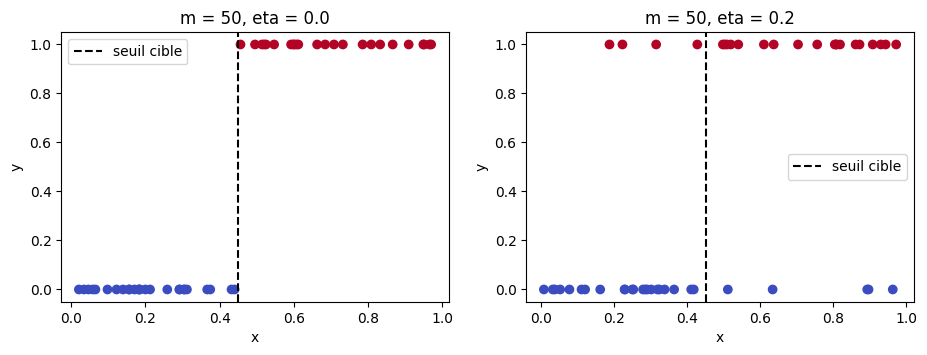

In [ ]:
def generer_donnees(m, eta=0.0):
    """m points uniformes sur [0,1], labels = 1 si x > THETA, puis bruit eta."""
    X = np.random.uniform(0, 1, m)
    y = (X > THETA).astype(int)
    flip = np.random.rand(m) < eta #quels labels sont inversés
    y[flip] = 1 - y[flip]
    return X, y

#visualisation : m = 50, sans bruit puis avec bruit
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, eta in zip(axes, [0.0, ETA]):
    X, y = generer_donnees(50, eta)
    ax.scatter(X, y, c=y, cmap="coolwarm")
    ax.axvline(THETA, color="k", linestyle="--", label="seuil cible")
    ax.set_title(f"m = 50, eta = {eta}")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.legend()
plt.show()

**Commentaire :** sans bruit, un seul seuil sépare parfaitement les deux classes. Avec bruit ($\eta = 0.2$), on voit des points rouges à gauche du seuil et des points bleus à droite : aucun seuil ne peut classer tous les points correctement.

## 2. Implémentation de l'ERM
**Stratégie :** l'erreur empirique d'un seuil ne change que quand le seuil passe un point d'entraînement. Il suffit donc de tester un nombre fini de seuils : $0$, $1$ et les milieux entre deux points consécutifs (après tri). On calcule l'erreur empirique de chacun et on garde le meilleur. En cas d'égalité, on garde le premier trouvé (tout seuil de plus petite erreur est un ERM valide).

In [ ]:
def predire(X, theta):
    return (X > theta).astype(int)

def erm_seuil(X, y):
  """Teste tous les seuils candidats et garde celui de plus petite erreur empirique."""
  ordre = np.argsort(X)
  xs, ys = X[ordre], y[ordre]
  #les seuils pertinents sont entre deux points consécutifs
  candidats = np.concatenate(([0.0], (xs[:-1] + xs[1:]) / 2, [1.0]))

  best_theta, min_err = 0.0, 1.0
  for t in candidats:
    err = np.mean((X > t) != y)
    if err < min_err:
      min_err = err
      best_theta = t
  return best_theta, min_err

**Commentaire :** cette méthode est simple, elle demande $m+1$ évaluations de l'erreur, ce qui reste rapide pour $m \le 200$.

## 3. Évaluation des performances
Pour chaque $m$ (cadre réalisable), on entraîne l'ERM une fois, puis on calcule :
- l'erreur empirique sur les données d'entraînement ;
- l'erreur vraie, estimée sur un grand jeu de test indépendant (20 000 points).

  m | theta_hat | erreur empirique | erreur vraie (test)
   5 |     0.000 |            0.000 | 0.4506
  10 |     0.453 |            0.000 | 0.0035
  20 |     0.489 |            0.000 | 0.0397
  50 |     0.446 |            0.000 | 0.0043
 100 |     0.445 |            0.000 | 0.0044
 200 |     0.448 |            0.000 | 0.0027


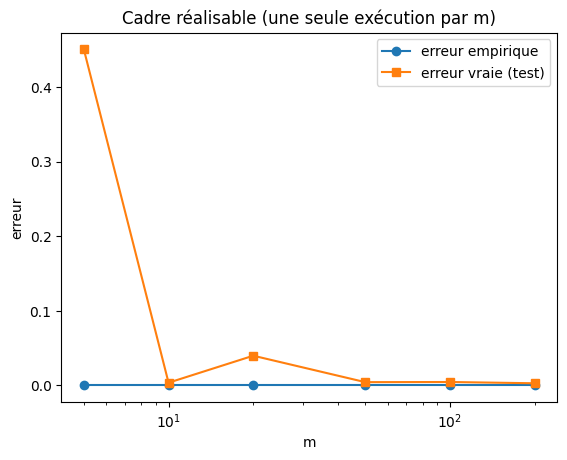

In [ ]:
#jeu de test indépendant, grand (sans bruit)
X_test, y_test = generer_donnees(M_TEST, eta=0.0)

def erreur_vraie(theta, X_t, y_t):
    return np.mean(predire(X_t, theta) != y_t)

print("  m | theta_hat | erreur empirique | erreur vraie (test)")
err_emp_list, err_vraie_list = [], []
for m in TAILLES:
    X, y = generer_donnees(m)
    theta_hat, err_emp = erm_seuil(X, y)
    err_vraie = erreur_vraie(theta_hat, X_test, y_test)
    err_emp_list.append(err_emp); err_vraie_list.append(err_vraie)
    print(f"{m:4d} | {theta_hat:9.3f} | {err_emp:16.3f} | {err_vraie:.4f}")

plt.plot(TAILLES, err_emp_list, "o-", label="erreur empirique")
plt.plot(TAILLES, err_vraie_list, "s-", label="erreur vraie (test)")
plt.xscale("log"); plt.xlabel("m"); plt.ylabel("erreur")
plt.title("Cadre réalisable (une seule exécution par m)")
plt.legend(); plt.show()

**Commentaire :**
- L'erreur empirique vaut toujours $0$ : en réalisable, un seuil parfait existe et l'ERM le trouve.
- L'erreur vraie est plus grande que $0$ et globalement elle diminue quand $m$ augmente ($\approx 0.004$ à $m = 100$ et $m = 50$, $\approx 0.003$ à $m = 200$).
- Avec une seule exécution, les résultats sont très variables : pour $m = 5$ l'erreur vraie est $0.45$ car, par malchance, tous les points d'entraînement avaient le même label (l'ERM a alors choisi $\theta = 0$, qui est bien sans erreur sur l'échantillon mais mauvais en général), et $m = 20$ donne une erreur plus grande que $m = 10$. C'est pourquoi la section suivante répète l'expérience plusieurs fois.
- Pour $m$ petit, l'erreur empirique ($0$) sous-estime beaucoup l'erreur vraie : l'écart de généralisation est grand.

## 4. Vérification expérimentale du PAC (réalisable)
Pour chaque $m$, on répète 500 fois : tirer un échantillon, appliquer l'ERM, calculer l'erreur vraie sur le jeu de test. On estime ensuite $\Pr(L(h) > \varepsilon)$ avec $\varepsilon = 0.05$ par la proportion de répétitions où l'erreur dépasse $\varepsilon$.

  m | Pr(L(h) > eps)
   5 | 0.608
  10 | 0.356
  20 | 0.140
  50 | 0.006
 100 | 0.000
 200 | 0.000


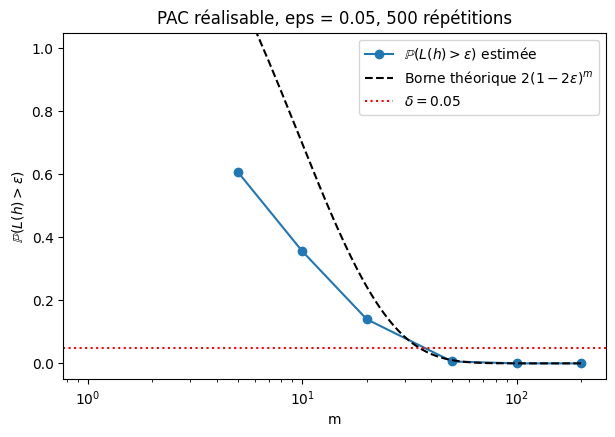

In [ ]:
def experience(eta, n_rep=N_REP):
  """Pour chaque m, répète l'apprentissage n_rep fois. Retourne les erreurs empiriques et vraies.
  """
  #test set avec le même bruit que l'entraînement, c'est le risque L(h)
  X_t, y_t = generer_donnees(M_TEST, eta)
  emp = {m: [] for m in TAILLES}
  vrai = {m: [] for m in TAILLES}
  for m in TAILLES:
    for _ in range(n_rep):
      X, y = generer_donnees(m, eta)
      theta_hat, e = erm_seuil(X, y)
      emp[m].append(e)
      vrai[m].append(erreur_vraie(theta_hat, X_t, y_t))
  return emp, vrai


emp_real, vrai_real = experience(eta=0.0)

#Pr(L(h) > eps)  (en réalisable, le risque minimal est 0)
proba_real = [np.mean(np.array(vrai_real[m]) > EPS) for m in TAILLES]

print("  m | Pr(L(h) > eps)")
for m, p in zip(TAILLES, proba_real):
  print(f"{m:4d} | {p:.3f}")

#tracé du graphique
plt.figure(figsize=(7, 4.5))
plt.plot(TAILLES, proba_real, "o-", label=r"$\mathbb{P}(L(h) > \varepsilon)$ estimée")

m_range = np.arange(1, 201)
borne = 2 * (1 - 2 * EPS) ** m_range
plt.plot(m_range, borne, "k--", label=r"Borne théorique $2(1-2\varepsilon)^m$")

plt.axhline(DELTA, color="red", linestyle=":", label=rf"$\delta = {DELTA}$")
plt.xscale("log")
plt.ylim(-0.05, 1.05)
plt.xlabel("m")
plt.ylabel(r"$\mathbb{P}(L(h) > \varepsilon)$")
plt.title(f"PAC réalisable, eps = {EPS}, {N_REP} répétitions")
plt.legend()
plt.show()

**Commentaire :** la probabilité de dépasser $\varepsilon$ diminue très vite quand $m$ augmente : $\approx 0.61$ pour $m = 5$, $0.36$ pour $m = 10$, $0.14$ pour $m = 20$, $0.006$ pour $m = 50$ et $0$ pour $m = 100$ et $200$.

On remarque que notre courbe empirique reste bien sous la borne théorique $2(1 - 2\varepsilon)^m$. En posant $2(1 - 2\varepsilon)^m \le \delta$, la théorie garantit la condition dès $m \ge \ln(2/\delta) / (2\varepsilon) \approx 37$. Sur notre grille de valeurs, $m = 50$ est donc bien le premier à passer sous le seuil $\delta = 0.05$.

C'est exactement ce que dit le cadre PAC : pour $\varepsilon$ et $\delta$ fixés, il existe une taille d'échantillon $m$ suffisante à partir de laquelle l'ERM renvoie, avec probabilité au moins $1 - \delta$, un classifieur ayant une erreur au plus $\varepsilon$.

## 5. Du PAC au PAC agnostique
On ajoute du bruit $\eta = 0.2$ sur les labels, pour l'entraînement et pour le jeu de test. La meilleure erreur possible avec un seuil n'est plus $0$ mais $\eta = 0.2$ (le seuil $\theta^*$ se trompe quand le label est inversé). On compare donc maintenant $L(h)$ à $\eta$.

  m | err. empirique moy. | Pr(err. empirique = 0) | err. vraie moy.
   5 |               0.114 |                  0.512 | 0.3241
  10 |               0.145 |                  0.154 | 0.2819
  20 |               0.164 |                  0.020 | 0.2501
  50 |               0.189 |                  0.000 | 0.2215
 100 |               0.194 |                  0.000 | 0.2113
 200 |               0.196 |                  0.000 | 0.2047


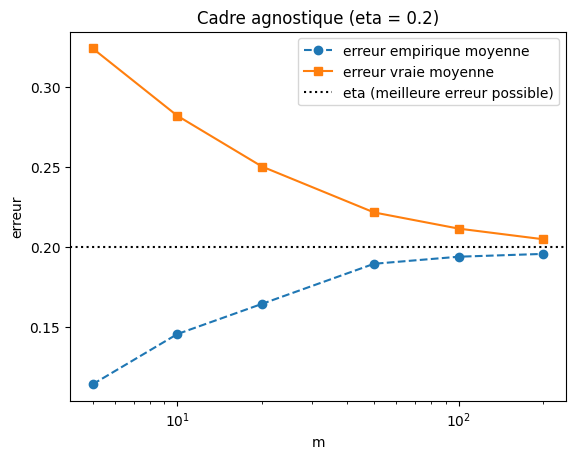

In [ ]:
emp_agn, vrai_agn = experience(eta=ETA)

print("  m | err. empirique moy. | Pr(err. empirique = 0) | err. vraie moy.")
for m in TAILLES:
    p_zero = np.mean(np.array(emp_agn[m]) == 0)
    print(f"{m:4d} | {np.mean(emp_agn[m]):19.3f} | {p_zero:22.3f} | {np.mean(vrai_agn[m]):.4f}")

plt.plot(TAILLES, [np.mean(emp_agn[m]) for m in TAILLES], "o--", label="erreur empirique moyenne")
plt.plot(TAILLES, [np.mean(vrai_agn[m]) for m in TAILLES], "s-", label="erreur vraie moyenne")
plt.axhline(ETA, color="k", linestyle=":", label="eta (meilleure erreur possible)")
plt.xscale("log"); plt.xlabel("m"); plt.ylabel("erreur")
plt.title(f"Cadre agnostique (eta = {ETA})")
plt.legend(); plt.show()

**Commentaire (erreur empirique et erreur vraie avec bruit) :**
- L'erreur empirique ne peut plus rester à $0$ : elle est nulle seulement pour de très petits échantillons ($51\%$ des cas à $m = 5$, $15\%$ à $m = 10$, $2\%$ à $m = 20$, puis $0\%$). Quand $m$ augmente, elle se rapproche de $\eta$ ($\approx 0.196$ à $m = 200$).
- L'erreur empirique est trop optimiste pour $m$ petit ($0.11$ contre une vraie erreur de $0.32$ à $m = 5$) : l'ERM s'adapte au bruit des données.
- L'erreur vraie diminue avec $m$ mais ne descend jamais sous $\eta = 0.2$ : elle passe de $0.32$ ($m = 5$) à $0.205$ ($m = 200$).

  m | réalisable : Pr(L > eps) | agnostique : Pr(L > eta + eps)
   5 |                    0.608 | 0.648
  10 |                    0.356 | 0.510
  20 |                    0.140 | 0.312
  50 |                    0.006 | 0.128
 100 |                    0.000 | 0.040
 200 |                    0.000 | 0.004


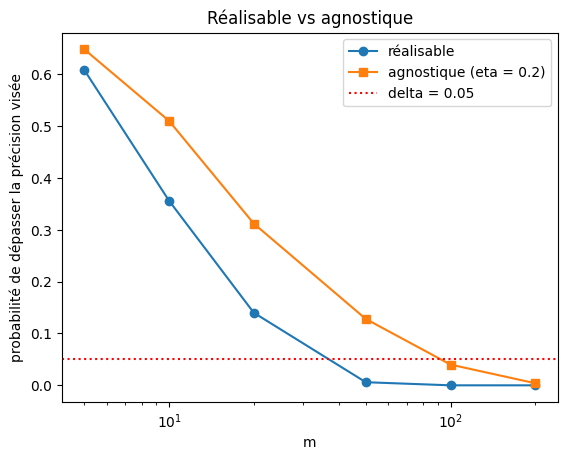

In [ ]:
#dans le cas agnostique on compare L(h) à la meilleure erreur possible (eta) : Pr(L(h) > eta + eps)
proba_agn = [np.mean(np.array(vrai_agn[m]) > ETA + EPS) for m in TAILLES]

print("  m | réalisable : Pr(L > eps) | agnostique : Pr(L > eta + eps)")
for m, p1, p2 in zip(TAILLES, proba_real, proba_agn):
    print(f"{m:4d} | {p1:24.3f} | {p2:.3f}")

plt.plot(TAILLES, proba_real, "o-", label="réalisable")
plt.plot(TAILLES, proba_agn, "s-", label=f"agnostique (eta = {ETA})")
plt.axhline(DELTA, color="red", linestyle=":", label="delta = 0.05")
plt.xscale("log"); plt.xlabel("m"); plt.ylabel("probabilité de dépasser la précision visée")
plt.title("Réalisable vs agnostique")
plt.legend(); plt.show()

**Commentaire (réalisable vs agnostique) :**
- Avec bruit, plus de données améliorent toujours la généralisation : $\Pr(L(h) > \eta + \varepsilon)$ tend aussi vers $0$ ($0.65$ à $m = 5$, $0.13$ à $m = 50$, $0.004$ à $m = 200$).
- Mais la convergence est plus lente : pour passer sous $\delta = 0.05$, il faut $m = 100$ avec bruit contre $m = 50$ sans bruit. À $m = 50$, la probabilité vaut $0.006$ sans bruit et $0.13$ avec bruit.
- On retrouve les deux cadres du cours : en PAC réalisable on suppose qu'un classifieur parfait existe ($L = 0$) et on veut $L(h) \le \varepsilon$ ; en PAC agnostique on ne suppose rien et on veut seulement $L(h) \le \min_h L(h) + \varepsilon$.

## 6. Conclusion et réponses aux questions

### Réponses aux questions de l'énoncé :
- **L'erreur empirique peut-elle encore atteindre zéro en agnostique ?**  
  Non, sauf parfois sur de très petits échantillons ($m = 5$ ou $10$) par simple hasard d'échantillonnage. Dès que $m$ grandit ($m \ge 20$), il y a quasi systématiquement des labels bruités contradictoires, donc aucun seuil ne peut séparer parfaitement les données : l'erreur empirique ne peut plus être nulle et se rapproche du taux de bruit $\eta = 0.2$.
- **Est-ce qu'augmenter le nombre d'exemples d'entraînement améliore encore la généralisation ?**  
  Oui. Même avec du bruit, avoir plus de données réduit la variance et force l'ERM à trouver un seuil très proche du seuil optimal $\theta^* = 0.45$. L'erreur vraie sur le jeu de test diminue au fur et à mesure que $m$ augmente et se rapproche de la meilleure erreur possible (le risque de Bayes $\eta = 0.2$).
- **Lien avec les cadres théoriques PAC et PAC agnostique vus en cours :**  
  - En **PAC réalisable**, on pose l'hypothèse qu'un classifieur parfait existe dans la classe ($L(h^*) = 0$). L'ERM annule toujours l'erreur empirique, l'erreur vraie converge vers 0, et la condition $\mathbb{P}(L(h) > \varepsilon) \le \delta$ est vérifiée très rapidement (dès $m = 50$ ici).
  - En **PAC agnostique**, on ne fait aucune hypothèse sur la séparabilité des données. On ne peut pas garantir que l'erreur absolue est inférieure à $\varepsilon$, mais que l'excès de risque par rapport au meilleur classifieur de la classe est borné : $L(h) \le \min_{h \in \mathcal{H}} L(h) + \varepsilon$ (ici $L(h) \le \eta + \varepsilon$).
  - La convergence est plus lente en agnostique : il faut plus d'exemples pour atteindre la même confiance $\delta$ (ici $m = 100$ contre $m = 50$ en réalisable).